### GrimAge V2 (2022) Epigenetic Clock

This notebook demonstrates the `GrimAgeV2` clock class from `epigenetic_clocks.py`.

All the reusable, clock-agnostic logic (evaluation metrics and validation against
published benchmarks) lives in `epigenetic_clocks.py` as plain functions, so it can
be reused by other clocks (Horvath, Hannum, PhenoAge, ...). Everything specific to
GrimAge V2 (the long-format coefficient file, the two-stage prediction architecture,
the paper's exact metric column names/tolerances) is encapsulated in the `GrimAgeV2`
class.

**Architecture overview:**
GrimAge V2 is a two-stage model:
1. **Stage 1** — Ten protein/smoking proxy variables (DNAmGDF15, DNAmB2M, etc.) are
   each predicted from a separate linear combination of CpG beta-values ± chronological
   age.
2. **Stage 2** — A COX linear predictor is formed from the ten stage-1 outputs plus
   chronological age and biological sex. The raw predictor is standardised to a
   biological age in years via stored population mean/SD parameters.

Because GrimAge uses chronological age and biological sex during prediction (not just
for evaluation), both **must** be supplied to `predict()` and `run()`.

Reference: Lu AT, et al. (2022) *DNA methylation GrimAge version 2.*
Aging, 14(23): 9484–9549. https://doi.org/10.18632/aging.204434


In [3]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt

#from epigenetic_clocks import GrimAgeV2

In [4]:
# ── Load your real data ───────────────────────────────────────────────
with open('/work/gr-fe/bryan/EpiHydra/data/02_processed/GSE40279/methylation.pkl', 'rb') as file:
    data = pickle.load(file)

In [5]:
data

{'meta':             ID      Organism  platform   age gender       tissue  horvath_age  \
 0    GSM989827  Homo sapiens  GPL13534  67.0      F  whole blood    52.161142   
 1    GSM989828  Homo sapiens  GPL13534  89.0      F  whole blood    75.446216   
 2    GSM989829  Homo sapiens  GPL13534  66.0      F  whole blood    62.602883   
 3    GSM989830  Homo sapiens  GPL13534  64.0      F  whole blood    54.249671   
 4    GSM989831  Homo sapiens  GPL13534  62.0      F  whole blood    62.947226   
 ..         ...           ...       ...   ...    ...          ...          ...   
 651  GSM990623  Homo sapiens  GPL13534  78.0      F  whole blood    72.093558   
 652  GSM990624  Homo sapiens  GPL13534  71.0      M  whole blood    74.341380   
 653  GSM990625  Homo sapiens  GPL13534  68.0      M  whole blood    67.425405   
 654  GSM990626  Homo sapiens  GPL13534  61.0      F  whole blood    60.365840   
 655  GSM990627  Homo sapiens  GPL13534  73.0      M  whole blood    77.332985   
 
      

In [6]:
data['CpG']

,GSM989827,GSM989828,GSM989829,GSM989830,GSM989831,GSM989832,GSM989833,GSM989834,GSM989835,GSM989836,...,GSM990618,GSM990619,GSM990620,GSM990621,GSM990622,GSM990623,GSM990624,GSM990625,GSM990626,GSM990627
ID_REF,,,,,,,,,,,,,,,,,,,,,
cg00000029,0.464197,0.454883,0.485764,0.480785,0.501220,0.499918,0.485852,0.512442,0.518155,0.417986,...,0.560958,0.472081,0.508502,0.505193,0.443411,0.527496,0.588331,0.362994,0.499145,0.458600
cg00000108,0.941091,0.939033,0.918802,0.929908,0.934548,0.950543,0.925855,0.941330,0.938528,0.933814,...,0.934699,0.978612,0.922024,0.963052,0.992631,0.958173,0.982450,0.954392,0.931690,0.974731
cg00000109,0.911182,0.596455,0.870333,0.889689,0.890450,0.898493,0.893972,0.892010,0.900841,0.883539,...,0.881957,0.926289,0.930091,0.946547,0.929131,0.922034,0.855145,0.927184,0.900938,0.829869
cg00000165,0.132014,0.206917,0.162861,0.197780,0.148437,0.224093,0.400489,0.194553,0.134710,0.204569,...,0.199883,0.165116,0.210248,0.177351,0.118742,0.223068,0.162180,0.196430,0.167477,0.170578
cg00000236,0.717861,0.723935,0.719196,0.704061,0.754913,0.829192,0.723782,0.695142,0.731872,0.742913,...,0.759011,0.792883,0.730367,0.783830,0.787089,0.778959,0.796868,0.713020,0.730215,0.782844
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ch.9.98937537R,0.042808,0.036811,0.042844,0.042258,0.039613,0.035309,0.031304,0.031119,0.031373,0.039919,...,0.051150,0.049286,0.071773,0.056795,0.041892,0.049571,0.055904,0.048526,0.056429,0.040701
ch.9.98957343R,0.052589,0.053343,0.045973,0.048733,0.039254,0.043023,0.037075,0.048277,0.041296,0.049226,...,0.051119,0.058118,0.059010,0.057837,0.037403,0.033060,0.062442,0.041087,0.047835,0.027499
ch.9.98959675F,0.035624,0.075618,0.126421,0.084051,0.165874,0.088889,0.097599,0.084294,0.052505,0.098726,...,0.077570,0.087988,0.098583,0.066481,0.001334,0.093414,0.101100,0.049857,0.028896,0.000000


In [7]:
data['meta']

,ID,Organism,platform,age,gender,tissue,horvath_age,hannum_age,phenoage_age,grimageadapter_age,chron_age
0,GSM989827,Homo sapiens,GPL13534,67.0,F,whole blood,52.161142,67.134750,50.851113,70.287890,67.0
1,GSM989828,Homo sapiens,GPL13534,89.0,F,whole blood,75.446216,86.167865,72.484114,86.082642,89.0
2,GSM989829,Homo sapiens,GPL13534,66.0,F,whole blood,62.602883,68.953058,58.508157,81.460442,66.0
3,GSM989830,Homo sapiens,GPL13534,64.0,F,whole blood,54.249671,68.895559,59.575270,76.333641,64.0
4,GSM989831,Homo sapiens,GPL13534,62.0,F,whole blood,62.947226,67.932521,54.271417,65.688970,62.0
...,...,...,...,...,...,...,...,...,...,...,...
651,GSM990623,Homo sapiens,GPL13534,78.0,F,whole blood,72.093558,79.834723,70.632765,77.373776,78.0
652,GSM990624,Homo sapiens,GPL13534,71.0,M,whole blood,74.341380,76.036389,56.433978,73.868591,71.0
653,GSM990625,Homo sapiens,GPL13534,68.0,M,whole blood,67.425405,67.845801,52.784414,73.767427,68.0
654,GSM990626,Homo sapiens,GPL13534,61.0,F,whole blood,60.365840,65.590458,44.678518,65.199061,61.0


## 1. Load data and initialise the clock

In [42]:
# ── Load your real data ───────────────────────────────────────────────
with open('/work/gr-fe/bryan/EpiHydra/data/02_processed/GSE40279/methylation.pkl', 'rb') as file:
    data = pickle.load(file)

# Beta value matrix (rows = CpGs, columns = samples)
methylation = data['CpG']

# Chronological ages, indexed by sample ID.
# GrimAge requires these at prediction time (not just for evaluation).
chron_ages = data['meta'].set_index('ID')['age']

# Biological sex indicator: True / 1 = female, False / 0 = male.
# Must be aligned with methylation column order.
female = data['meta'].set_index('ID')['gender'] == 'female'  # adjust column name as needed

# ── Initialise the GrimAge V2 clock ─────────────────────────────────────
# Coefficients come from Lu et al. (2022) supplementary data.
# Expected columns: 'Y.pred' (component name), 'var' (CpG / covariate), 'beta'.
clock = GrimAgeV2(coefficients_path="/work/gr-fe/bryan/EpiHydra/data/03_final/GrimAge/GrimAgeV2.csv")

Loaded GrimAge V2: 10 sub-components, 1030 unique CpG probes.


## 2. Predict DNAm age

Unlike single-stage clocks, `GrimAgeV2.predict()` requires `chron_ages` and `female`
because they are used internally during Stage 1 (some sub-components include age as a
covariate) and Stage 2 (the COX predictor includes age and sex).

The returned DataFrame contains:
- `DNAmAge` — GrimAge V2 biological age estimate in years
- `COX_lp` — raw (unstandardised) COX linear predictor
- One column per sub-component (e.g. `DNAmGDF15`, `DNAmB2M`, …)

In [43]:
results = clock.predict(methylation, chron_ages=chron_ages, female=female)
results

  → Predicting DNAmGDF15 …
⚠  [DNAmGDF15] 1 / 137 CpGs (0.7%) missing from methylation data.
  → Predicting DNAmB2M …
⚠  [DNAmB2M] 1 / 91 CpGs (1.1%) missing from methylation data.
  → Predicting DNAmCystatinC …
  → Predicting DNAmTIMP1 …
⚠  [DNAmTIMP1] 2 / 42 CpGs (4.8%) missing from methylation data.
  → Predicting DNAmADM …
⚠  [DNAmADM] 23 / 186 CpGs (12.4%) missing from methylation data.
  → Predicting DNAmPAI1 …
⚠  [DNAmPAI1] 11 / 211 CpGs (5.2%) missing from methylation data.
  → Predicting DNAmLeptin …
⚠  [DNAmLeptin] 32 / 187 CpGs (17.1%) missing from methylation data.
  → Predicting DNAmPACKYRS …
⚠  [DNAmPACKYRS] 3 / 172 CpGs (1.7%) missing from methylation data.
  → Predicting DNAmlogCRP …
⚠  [DNAmlogCRP] 11 / 132 CpGs (8.3%) missing from methylation data.
  → Predicting DNAmlogA1C …
⚠  [DNAmlogA1C] 5 / 86 CpGs (5.8%) missing from methylation data.


,DNAmAge,COX_lp,DNAmGDF15,DNAmB2M,DNAmCystatinC,DNAmTIMP1,DNAmADM,DNAmPAI1,DNAmLeptin,DNAmPACKYRS,DNAmlogCRP,DNAmlogA1C
SampleID,,,,,,,,,,,,
GSM989827,70.287890,15.877837,645.724251,1.574648e+06,624644.053872,34150.932401,442.366451,17383.884207,21189.734620,10.415259,0.611686,1.732460
GSM989828,86.082642,17.787467,885.241746,1.964136e+06,714325.986774,37969.158446,471.590894,16798.789956,23503.867476,13.493240,0.589844,1.746652
GSM989829,81.460442,17.228630,856.638077,1.568624e+06,641384.116858,34403.702265,451.960409,15524.448971,23019.234302,45.008868,0.987756,1.742347
GSM989830,76.333641,16.608785,804.797290,1.653871e+06,643568.109096,34557.098342,440.651603,20246.184649,22996.401073,24.945776,1.054189,1.748820
GSM989831,65.688970,15.321814,625.530116,1.669432e+06,622221.668314,33389.094358,437.945583,18587.487060,22776.439388,0.667093,0.382950,1.788528
...,...,...,...,...,...,...,...,...,...,...,...,...
GSM990623,77.373776,16.734540,856.366371,1.691918e+06,679575.315864,36101.663326,449.798783,16935.719036,22771.556087,9.316304,0.488707,1.750351
GSM990624,73.868591,16.310754,847.603528,1.631243e+06,647125.100547,35974.316716,420.819854,18061.357933,23331.646060,6.861032,0.896999,1.763347
GSM990625,73.767427,16.298523,773.979878,1.730683e+06,662319.764653,35073.863404,447.694253,19511.457893,22390.515341,11.998810,0.339486,1.770444


## 3. Compare to chronological age

In [44]:
comparison = results[["DNAmAge"]].join(chron_ages.rename("ChronAge"))
comparison["AgeAcceleration"] = comparison["DNAmAge"] - comparison["ChronAge"]
comparison

,DNAmAge,ChronAge,AgeAcceleration
SampleID,,,
GSM989827,70.287890,67.0,3.287890
GSM989828,86.082642,89.0,-2.917358
GSM989829,81.460442,66.0,15.460442
GSM989830,76.333641,64.0,12.333641
GSM989831,65.688970,62.0,3.688970
...,...,...,...
GSM990623,77.373776,78.0,-0.626224
GSM990624,73.868591,71.0,2.868591
GSM990625,73.767427,68.0,5.767427


In [45]:
metrics = clock.compute_metrics(
    comparison["ChronAge"],
    comparison["DNAmAge"],
    age_accel_method="difference",
)
metrics

,"Cor(Age, DNAmGrimAge)",Median Absolute Error (years),Median Age Acceleration
0,0.9216,8.9161,8.8744


## 4. Visualise

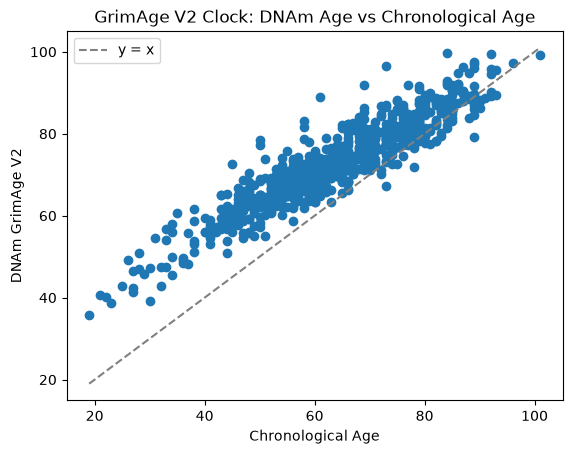

In [46]:
plt.scatter(comparison["ChronAge"], comparison["DNAmAge"])
plt.xlabel("Chronological Age")
plt.ylabel("DNAm GrimAge V2")
plt.plot(
    [comparison["ChronAge"].min(), comparison["ChronAge"].max()],
    [comparison["ChronAge"].min(), comparison["ChronAge"].max()],
    linestyle="--", color="grey", label="y = x",
)
plt.legend()
plt.title("GrimAge V2 Clock: DNAm Age vs Chronological Age")
plt.show()

### 4b. (Optional) Inspect sub-component predictions

The full `results` DataFrame also contains the 10 intermediate protein/smoking proxy
predictions produced in Stage 1, which can be useful for downstream analyses.

In [47]:
sub_components = [
    "DNAmGDF15", "DNAmB2M", "DNAmCystatinC", "DNAmTIMP1", "DNAmADM",
    "DNAmPAI1", "DNAmLeptin", "DNAmPACKYRS", "DNAmlogCRP", "DNAmlogA1C",
]
results[sub_components].describe().round(3)

,DNAmGDF15,DNAmB2M,DNAmCystatinC,DNAmTIMP1,DNAmADM,DNAmPAI1,DNAmLeptin,DNAmPACKYRS,DNAmlogCRP,DNAmlogA1C
count,656.000,656.000,656.000,656.000,656.000,656.000,656.000,656.000,656.000,656.000
mean,771.389,1643981.817,636293.985,34407.471,438.928,19338.285,22700.875,13.535,0.988,1.777
std,255.494,207473.300,50574.357,2217.833,27.409,2494.425,1893.368,8.981,0.447,0.030
min,-38.417,916438.527,471759.765,27494.332,342.029,11785.098,16881.786,-9.351,-0.772,1.685
25%,612.624,1504021.026,603839.716,32939.423,421.545,17662.453,21493.021,7.620,0.687,1.757
50%,751.147,1650066.120,639856.770,34390.052,440.411,19377.779,22565.771,11.461,0.997,1.776
75%,891.439,1793521.560,671080.180,36061.580,458.260,21019.082,23930.863,17.431,1.275,1.796
max,1854.596,2178742.964,770448.695,39967.392,531.633,27109.606,30694.411,45.799,2.794,1.901


## 5. Validate against published (paper) results

Compare the metrics computed above against the values published for this
dataset in Lu et al. (2022)'s supplementary tables.

In [48]:
paper_results = {
    "Cor(Age, DNAmGrimAge)" : 0.9, 
    "Median Absolute Error (years)" : 6.6 , 
    "Median Age Acceleration" : np.nan
}

In [49]:
validation = clock.validate(
    metrics,
    pd.DataFrame(paper_results , index=[0]),
    dataset_name=None,
)
validation


  Clock Validation — None
                          Yours  Paper  Abs. Diff  Tolerance  Status
Metric                                                              
Cor(Age, DNAmGrimAge)    0.9216    0.9     0.0216       0.05  ✓ Pass
Median Absolute Error    8.9161    6.6     2.3161       0.50  ✗ Fail
Median Age Acceleration  8.8744    NaN        NaN       0.50  ✗ Fail
  ✗ Outside tolerance: Median Absolute Error, Median Age Acceleration
  Check: CpG preprocessing, age transformation,
         sample filtering, or training CpG selection.



,Yours,Paper,Abs. Diff,Tolerance,Status
Metric,,,,,
"Cor(Age, DNAmGrimAge)",0.9216,0.9,0.0216,0.05,✓ Pass
Median Absolute Error,8.9161,6.6,2.3161,0.50,✗ Fail
Median Age Acceleration,8.8744,NaN,NaN,0.50,✗ Fail


## 6. (Optional) One-shot pipeline

`GrimAgeV2.run()` bundles prediction + comparison + metrics into a single call,
useful once you trust the individual steps above.

Unlike single-stage clock `run()` methods, `chron_ages` and `female` are **required**
(not optional) because GrimAge uses them during prediction.

In [50]:
out = clock.run(
    methylation,
    chron_ages=chron_ages,
    female=female,
    age_accel_method="difference",
)
out["metrics"]

  → Predicting DNAmGDF15 …
⚠  [DNAmGDF15] 1 / 137 CpGs (0.7%) missing from methylation data.
  → Predicting DNAmB2M …
⚠  [DNAmB2M] 1 / 91 CpGs (1.1%) missing from methylation data.
  → Predicting DNAmCystatinC …
  → Predicting DNAmTIMP1 …
⚠  [DNAmTIMP1] 2 / 42 CpGs (4.8%) missing from methylation data.
  → Predicting DNAmADM …
⚠  [DNAmADM] 23 / 186 CpGs (12.4%) missing from methylation data.
  → Predicting DNAmPAI1 …
⚠  [DNAmPAI1] 11 / 211 CpGs (5.2%) missing from methylation data.
  → Predicting DNAmLeptin …
⚠  [DNAmLeptin] 32 / 187 CpGs (17.1%) missing from methylation data.
  → Predicting DNAmPACKYRS …
⚠  [DNAmPACKYRS] 3 / 172 CpGs (1.7%) missing from methylation data.
  → Predicting DNAmlogCRP …
⚠  [DNAmlogCRP] 11 / 132 CpGs (8.3%) missing from methylation data.
  → Predicting DNAmlogA1C …
⚠  [DNAmlogA1C] 5 / 86 CpGs (5.8%) missing from methylation data.


,"Cor(Age, DNAmGrimAge)",Median Absolute Error (years),Median Age Acceleration
0,0.9216,8.9161,8.8744
